# Implementación de un modelo de deep learning

## Alfredo Alejandro Soto Herrera - A01711368

| Observación | Diagnóstico | Mejora propuesta |
|---|---|---|
| Ambas fases alcanzaron el máximo de épocas y la pérdida de validación seguía bajando | El entrenamiento no había convergido | Entrenar más tiempo (más épocas con early stopping) |
| El fine-tuning de 40 capas dio +9.4 puntos de accuracy | Adaptar más capas de la red a los autos vale la pena | Descongelar más capas (100) |
| Train 83 % contra val 63 %: brecha de ~20 puntos | Sobreajuste: la red empieza a memorizar | Regularización: más augmentation, dropout y label smoothing |

---

Para atender esas observaciones se realizaron los siguientes experimentos:

| Experimento | Cambio respecto al modelo 2 original |
|---|---|
| A_largo | Más épocas (fase 1: hasta 30, fase 2: hasta 80) |
| B_capas | A + descongelar 100 capas en lugar de 40 |
| C_regular | A + regularización (dropout 0.5, label smoothing 0.1, augmentation más fuerte) |
| D_combinada | B + C |



### Configuración y carga de datos

In [4]:
import os, sys, json, time, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix, f1_score

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)

# Parámetros
IMG_SIZE = int(os.environ.get("IMG_SIZE", 224))
BATCH_SIZE = 32
SEEDS = [int(s) for s in os.environ.get("SEEDS", "42,123").split(",")]
DATA_SEED = 42
LR_P1, LR_P2 = 1e-3, 1e-5
PRETRAINED = os.environ.get("PRETRAINED", "1") == "1"
EP_CAP = int(os.environ.get("EP_CAP", 0))

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU disponible:", gpus if gpus else "NO")
print("Semillas:", SEEDS)

TensorFlow: 2.21.0
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Semillas: [42, 123]


In [5]:
IN_COLAB = "google.colab" in sys.modules
WORK_DIR = "/content" if IN_COLAB else os.path.abspath("./work_mej")
os.makedirs(WORK_DIR, exist_ok=True)

ZIP_PATH = "/content/drive/MyDrive/car_dataset_processed.zip"
DATA_DIR = os.path.join(WORK_DIR, "car_data")
SAVE_DIR = "/content/drive/MyDrive/car_models" if IN_COLAB else os.path.join(WORK_DIR, "models")
ADJ_DIR = os.path.join(SAVE_DIR, "ajustes")      # modelo CNN
TL_DIR = os.path.join(SAVE_DIR, "transfer")      # modelo TL
IMP_DIR = os.path.join(SAVE_DIR, "mejoras")

env_dir = os.environ.get("CAR_PROC_DIR")
if env_dir:
    DATA_DIR = env_dir
elif not os.path.isdir(os.path.join(DATA_DIR, "train")):
    if IN_COLAB:
        from google.colab import drive
        drive.mount("/content/drive")
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_DIR)

for root, dirs, _ in os.walk(DATA_DIR):
    if "train" in dirs and "val" in dirs and "test" in dirs:
        DATA_DIR = root
        break

if IN_COLAB and not os.path.isdir("/content/drive/MyDrive"):
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(IMP_DIR, exist_ok=True)

BASE_RESULTS_PATH = os.path.join(TL_DIR, "transfer_results.json")
assert os.path.exists(BASE_RESULTS_PATH), "Falta transfer_results.json"
BASE = json.load(open(BASE_RESULTS_PATH))
print("DATA_DIR:", DATA_DIR)
print("Resultados del modelo 2 original:", sorted(BASE.keys()))

DATA_DIR: /content/car_data
Resultados del modelo 2 original: ['transfer|123', 'transfer|42']


### Pipeline de datos

In [6]:
common = dict(image_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH_SIZE)
train_int = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "train"), shuffle=True, seed=DATA_SEED, label_mode="int", **common)
val_int   = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "val"),   shuffle=False, label_mode="int", **common)

class_names = train_int.class_names
NUM_CLASSES = len(class_names)
val_paths = val_int.file_paths
AUTOTUNE = tf.data.AUTOTUNE

def to_onehot(x, y):
    return x, tf.one_hot(y, NUM_CLASSES)

train_ds = train_int.map(to_onehot, num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
val_ds   = val_int.map(to_onehot, num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)
val_img  = val_int.map(lambda x, y: x, num_parallel_calls=AUTOTUNE).cache().prefetch(AUTOTUNE)

y_val = np.concatenate([y.numpy() for _, y in val_int])
print("Clases:", class_names)
print("Imágenes de validación:", len(y_val))

Found 1267 files belonging to 10 classes.
Found 270 files belonging to 10 classes.
Clases: ['Audi_R8', 'Audi_RS5', 'BMW_M3', 'BMW_M5', 'Chevrolet_Camaro', 'Ford_Mustang', 'Mercedes_AMG_GT', 'Nissan_GT_R', 'Porsche_911', 'Toyota_Supra']
Imágenes de validación: 270


### Construcción de los modelos

Mismo esquema que el modelo 2.

In [7]:
def make_augmentation(kind="base"):
    if kind == "strong":
        ops = [layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.20),
               layers.RandomTranslation(0.10, 0.10), layers.RandomContrast(0.20),
               layers.RandomBrightness(0.20, value_range=(0, 255))]
    else:
        ops = [layers.RandomFlip("horizontal"), layers.RandomRotation(0.05), layers.RandomZoom(0.10),
               layers.RandomContrast(0.10), layers.RandomBrightness(0.10, value_range=(0, 255))]
    return keras.Sequential(ops, name="augmentation")


BACKBONES = {"efficientnetb0": keras.applications.EfficientNetB0}


def build_model(backbone="efficientnetb0", dropout=0.3, aug="base", name="m2"):
    base = BACKBONES[backbone](include_top=False, weights="imagenet" if PRETRAINED else None,
                               input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = make_augmentation(aug)(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inputs, outputs, name=name), base


def n_params(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights)), int(model.count_params())

for bb in BACKBONES:
    m, b = build_model(bb)
    tr, tot = n_params(m)
    print(f"{bb:<16} capas en la base: {len(b.layers):>4} | parámetros totales: {tot:>11,} | entrenables en la fase 1: {tr:,}")
    del m, b

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
efficientnetb0   capas en la base:  238 | parámetros totales:   4,062,381 | entrenables en la fase 1: 12,810


### Experimentos

In [8]:
COMMON = dict(p1=30, p2=80, pat1=8, pat2=10)
EXPERIMENTS = {
    "A_largo":     dict(backbone="efficientnetb0", ft=40,  dropout=0.3, ls=0.0, aug="base",   desc="Entrenamiento más largo", **COMMON),
    "B_capas":     dict(backbone="efficientnetb0", ft=100, dropout=0.3, ls=0.0, aug="base",   desc="A + 100 capas descongeladas", **COMMON),
    "C_regular":   dict(backbone="efficientnetb0", ft=40,  dropout=0.5, ls=0.1, aug="strong", desc="A + regularización", **COMMON),
    "D_combinada": dict(backbone="efficientnetb0", ft=100, dropout=0.5, ls=0.1, aug="strong", desc="B + C", **COMMON),
}

EXPS_TO_RUN = list(EXPERIMENTS)

RESULTS_PATH = os.path.join(IMP_DIR, "improve_results.json")
RESULTS = json.load(open(RESULTS_PATH)) if os.path.exists(RESULTS_PATH) else {}
print("Corridas ya guardadas:", sorted(RESULTS.keys()))

Corridas ya guardadas: ['A_largo|123', 'A_largo|42', 'B_capas|123', 'B_capas|42', 'C_regular|123', 'C_regular|42', 'D_combinada|123', 'D_combinada|42', 'E_convnext|123', 'E_convnext|42']


In [9]:
def cap(n):
    return min(n, EP_CAP) if EP_CAP else n


def eval_model(model):
    tr_loss, tr_acc = model.evaluate(train_ds, verbose=0)
    va_loss, va_acc = model.evaluate(val_ds, verbose=0)
    probs = model.predict(val_ds, verbose=0)
    y_pred = probs.argmax(axis=1)
    f1_cls = f1_score(y_val, y_pred, average=None, labels=range(NUM_CLASSES), zero_division=0)
    rec_cls = confusion_matrix(y_val, y_pred, labels=range(NUM_CLASSES)).diagonal() / np.bincount(y_val, minlength=NUM_CLASSES)
    return dict(train_acc=float(tr_acc), val_acc=float(va_acc), val_macro_f1=float(f1_cls.mean()),
                f1_per_class=[float(v) for v in f1_cls], recall_per_class=[float(v) for v in rec_cls],
                y_pred=[int(v) for v in y_pred])


def progress_cb(tag):
    return keras.callbacks.LambdaCallback(on_epoch_end=lambda e, logs: print(
        f"   [{tag}] época {e + 1:>2} | acc {logs['accuracy']:.3f} | val_acc {logs['val_accuracy']:.3f}")
        if (e + 1) % 10 == 0 else None)


def run_experiment(exp, seed):
    key = f"{exp}|{seed}"
    if key in RESULTS:
        print(f"[{key}] ya existe, se omite.")
        return RESULTS[key]

    cfg = EXPERIMENTS[exp]
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)
    model, base = build_model(cfg["backbone"], cfg["dropout"], cfg["aug"], name=exp)
    loss = keras.losses.CategoricalCrossentropy(label_smoothing=cfg["ls"])
    t0 = time.time()

    # Fase 1: base congelada
    model.compile(optimizer=keras.optimizers.Adam(LR_P1), loss=loss, metrics=["accuracy"])
    print(f"[{key}] {cfg['desc']} | FASE 1 (base congelada)")
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=cap(cfg["p1"]), verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg["pat1"], restore_best_weights=True), progress_cb("F1")]).history
    p1 = eval_model(model)
    print(f"[{key}] fin fase 1 -> val_acc {p1['val_acc']:.3f} | macro-F1 {p1['val_macro_f1']:.3f}")

    # Fase 2: fine-tuning
    base.trainable = True
    for layer in base.layers[:-cfg["ft"]]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(LR_P2), loss=loss, metrics=["accuracy"])
    print(f"[{key}] FASE 2 (fine-tuning de {cfg['ft']} capas) | parámetros entrenables: {n_params(model)[0]:,}")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=cap(cfg["p2"]), verbose=0, callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=cfg["pat2"], restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7), progress_cb("F2")]).history
    p2 = eval_model(model)
    elapsed = time.time() - t0

    res = dict(exp=exp, seed=seed, params_total=n_params(model)[1], seconds=float(elapsed),
               epochs_p1=len(h1["loss"]), epochs_p2=len(h2["loss"]),
               phase1={k: p1[k] for k in ("val_acc", "val_macro_f1", "train_acc")},
               hist_val_acc=[float(x) for x in h1["val_accuracy"] + h2["val_accuracy"]],
               hist_train_acc=[float(x) for x in h1["accuracy"] + h2["accuracy"]], n_epochs_p1=len(h1["loss"]), **p2)
    RESULTS[key] = res
    json.dump(RESULTS, open(RESULTS_PATH, "w"))
    model.save(os.path.join(IMP_DIR, f"{exp}_seed{seed}.keras"))
    print(f"[{key}] listo en {elapsed / 60:.1f} min | FINAL val_acc {p2['val_acc']:.3f} | macro-F1 {p2['val_macro_f1']:.3f} | train_acc {p2['train_acc']:.3f}\n")
    return res

In [10]:
for seed in SEEDS:
    for exp in EXPS_TO_RUN:
        run_experiment(exp, seed)

[A_largo|42] ya existe, se omite.
[B_capas|42] ya existe, se omite.
[C_regular|42] ya existe, se omite.
[D_combinada|42] ya existe, se omite.
[A_largo|123] ya existe, se omite.
[B_capas|123] ya existe, se omite.
[C_regular|123] ya existe, se omite.
[D_combinada|123] ya existe, se omite.


### Resultados

In [11]:
def get(exp, seed):
    return BASE[f"transfer|{seed}"] if exp == "M2_original" else RESULTS[f"{exp}|{seed}"]

DONE = [e for e in ["M2_original"] + list(EXPERIMENTS) if all((f"{e}|{s}" in RESULTS) or (e == "M2_original") for s in SEEDS)]
DESC = {"M2_original": "EfficientNetB0 original (20 + 30 épocas máx.)", **{k: v["desc"] for k, v in EXPERIMENTS.items()}}

def ms(exp, field):
    v = np.array([get(exp, s)[field] for s in SEEDS])
    return v.mean(), (v.std(ddof=1) if len(v) > 1 else np.nan)

def fmt(m, s):
    return f"{100 * m:.1f}" + (f" ± {100 * s:.1f}" if not np.isnan(s) else "")

rows = []
for e in DONE:
    va, vs = ms(e, "val_acc"); f1, fs = ms(e, "val_macro_f1"); tr, ts = ms(e, "train_acc")
    ep = np.mean([get(e, s)["epochs_p1"] + get(e, s)["epochs_p2"] for s in SEEDS])
    mins = np.mean([get(e, s)["seconds"] for s in SEEDS]) / 60
    rows.append({"Experimento": e, "Descripción": DESC[e], "Parámetros": f"{get(e, SEEDS[0])['params_total']:,}",
                 "Train acc (%)": fmt(tr, ts), "Val acc (%)": fmt(va, vs), "Val macro-F1 (%)": fmt(f1, fs),
                 "Brecha (pts)": f"{100 * (tr - va):.1f}", "Épocas": f"{ep:.0f}", "Min/corrida": f"{mins:.1f}"})
summary = pd.DataFrame(rows).set_index("Experimento")
display(summary)

,Descripción,Parámetros,Train acc (%),Val acc (%),Val macro-F1 (%),Brecha (pts),Épocas,Min/corrida
Experimento,,,,,,,,
M2_original,EfficientNetB0 original (20 + 30 épocas máx.),"4,062,381",83.0 ± 0.3,62.8 ± 0.8,63.3 ± 1.0,20.2,50,4.0
A_largo,Entrenamiento más largo,"4,062,381",94.2 ± 0.8,68.1 ± 1.6,68.4 ± 1.1,26.1,108,7.8
B_capas,A + 100 capas descongeladas,"4,062,381",95.7 ± 0.6,70.2 ± 0.8,70.7 ± 1.4,25.6,84,6.9
C_regular,A + regularización,"4,062,381",84.2 ± 0.7,63.7 ± 0.0,63.5 ± 0.4,20.5,110,8.0
D_combinada,B + C,"4,062,381",91.6 ± 0.7,69.3 ± 0.5,69.5 ± 0.3,22.4,110,9.2


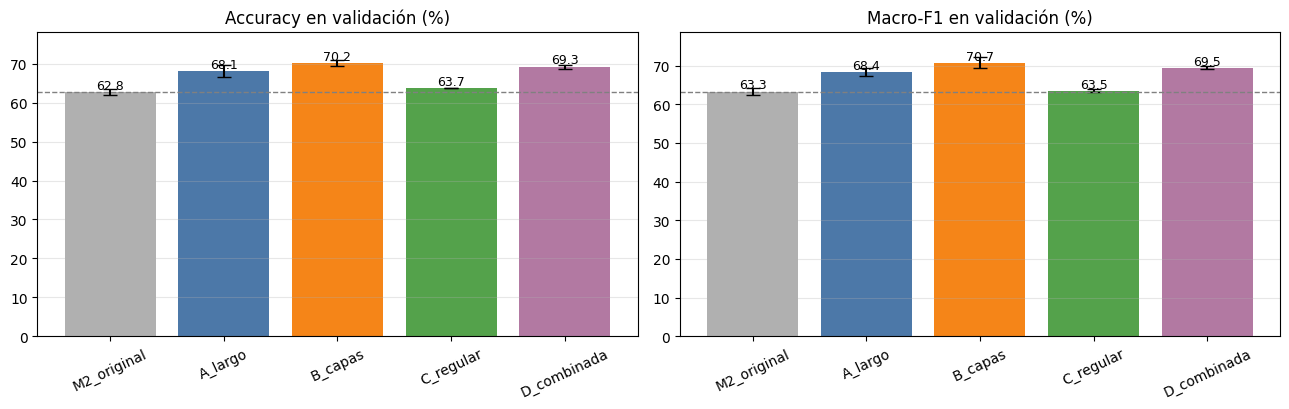

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
palette = ["#B0B0B0", "#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756"]
for a, field, title in zip(ax, ["val_acc", "val_macro_f1"], ["Accuracy en validación (%)", "Macro-F1 en validación (%)"]):
    means = [100 * ms(e, field)[0] for e in DONE]
    errs = [0 if np.isnan(ms(e, field)[1]) else 100 * ms(e, field)[1] for e in DONE]
    bars = a.bar(DONE, means, yerr=errs, capsize=5, color=palette[:len(DONE)])
    for b, m in zip(bars, means):
        a.text(b.get_x() + b.get_width() / 2, m + 0.8, f"{m:.1f}", ha="center", fontsize=9)
    a.axhline(means[0], color="gray", ls="--", lw=1)
    a.set_title(title); a.tick_params(axis="x", rotation=25); a.grid(axis="y", alpha=0.3); a.set_ylim(0, max(means) + 8)
plt.tight_layout(); plt.show()

Curvas de validación y F1 por clase

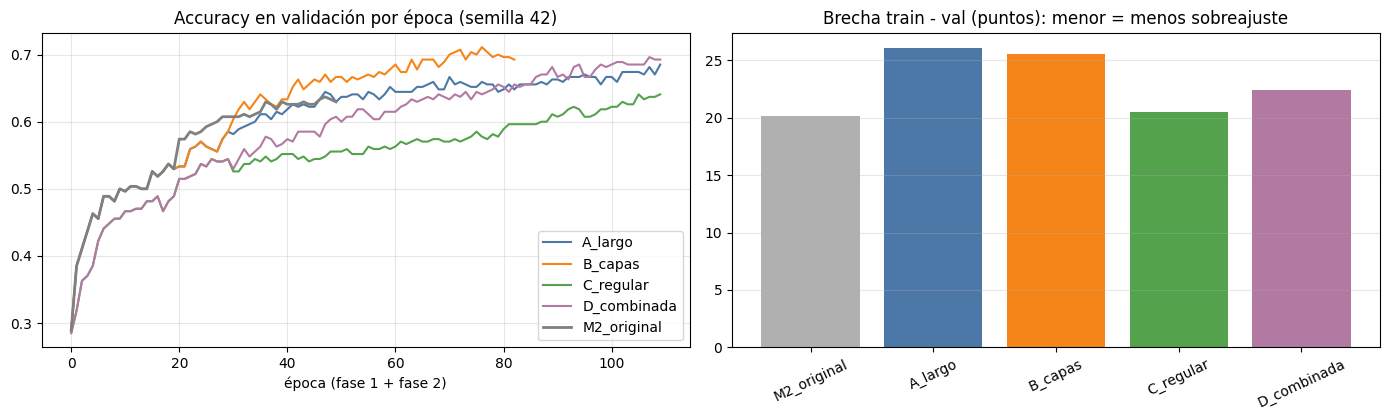

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
for e, c in zip(DONE[1:], palette[1:]):
    if e in EXPERIMENTS:
        ax[0].plot(RESULTS[f"{e}|{SEEDS[0]}"]["hist_val_acc"], label=e, color=c)
ax[0].plot(BASE[f"transfer|{SEEDS[0]}"]["hist1"]["val_accuracy"] + BASE[f"transfer|{SEEDS[0]}"]["hist2"]["val_accuracy"],
           label="M2_original", color="#808080", lw=2)
ax[0].set_title(f"Accuracy en validación por época (semilla {SEEDS[0]})"); ax[0].set_xlabel("época (fase 1 + fase 2)")
ax[0].grid(alpha=0.3); ax[0].legend()

gap = {e: 100 * (ms(e, "train_acc")[0] - ms(e, "val_acc")[0]) for e in DONE}
ax[1].bar(gap.keys(), gap.values(), color=palette[:len(DONE)])
ax[1].set_title("Brecha train - val (puntos): menor = menos sobreajuste"); ax[1].tick_params(axis="x", rotation=25); ax[1].grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()

In [14]:
f1_table = pd.DataFrame({e: np.mean([get(e, s)["f1_per_class"] for s in SEEDS], axis=0) for e in DONE}, index=class_names)
f1_table.loc["MACRO-F1"] = f1_table.mean()
display(f1_table.style.background_gradient(cmap="Blues", axis=None, vmin=0.2, vmax=0.9).format("{:.2f}"))

,M2_original,A_largo,B_capas,C_regular,D_combinada
Audi_R8,0.72,0.82,0.80,0.73,0.80
Audi_RS5,0.75,0.81,0.84,0.72,0.81
BMW_M3,0.52,0.62,0.65,0.54,0.62
BMW_M5,0.66,0.71,0.74,0.65,0.74
Chevrolet_Camaro,0.61,0.62,0.64,0.58,0.66
Ford_Mustang,0.64,0.67,0.67,0.64,0.65
Mercedes_AMG_GT,0.62,0.65,0.72,0.62,0.69
Nissan_GT_R,0.62,0.70,0.71,0.70,0.72
Porsche_911,0.64,0.61,0.69,0.57,0.63
Toyota_Supra,0.54,0.61,0.63,0.60,0.63


Mejor configuración y conclusión automática

Mejor experimento por macro-F1: B_capas - A + 100 capas descongeladas
Modelo 2 original -> accuracy 62.8% | macro-F1 0.633
B_capas           -> accuracy 70.2% | macro-F1 0.707
Mejora: +7.4 puntos de accuracy | +7.4 puntos de macro-F1 | margen de error ±5.5
-> La mejora supera el margen de error.


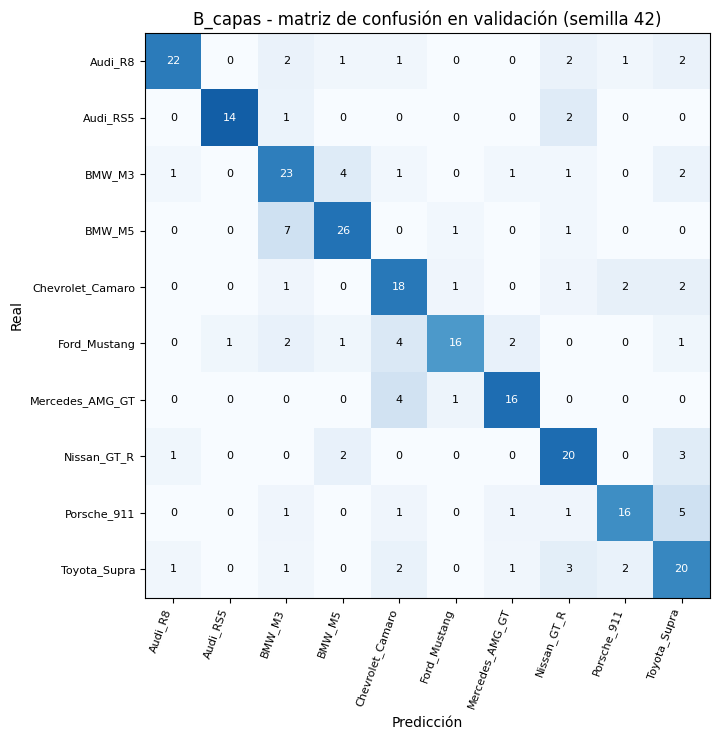

In [15]:
CANDIDATES = [e for e in DONE if e != "M2_original"]
BEST = max(CANDIDATES, key=lambda e: ms(e, "val_macro_f1")[0])
b_acc, b_acc_s = ms(BEST, "val_acc"); b_f1, _ = ms(BEST, "val_macro_f1")
o_acc, _ = ms("M2_original", "val_acc"); o_f1, _ = ms("M2_original", "val_macro_f1")
noise = 1.96 * np.sqrt(b_acc * (1 - b_acc) / len(y_val)) * 100

print(f"Mejor experimento por macro-F1: {BEST} - {DESC[BEST]}")
print(f"Modelo 2 original -> accuracy {o_acc:.1%} | macro-F1 {o_f1:.3f}")
print(f"{BEST:<17} -> accuracy {b_acc:.1%} | macro-F1 {b_f1:.3f}")
gain = 100 * (b_acc - o_acc)
print(f"Mejora: {gain:+.1f} puntos de accuracy | {100 * (b_f1 - o_f1):+.1f} puntos de macro-F1 | margen de error ±{noise:.1f}")
print("-> La mejora supera el margen de error." if gain > noise else "-> La mejora está dentro del margen de error: no se puede asegurar que sea real.")

# Matriz de confusión de la mejor configuración
cm = confusion_matrix(y_val, np.array(get(BEST, SEEDS[0])["y_pred"]), labels=range(NUM_CLASSES))
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(8.5, 7.5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(class_names, rotation=70, ha="right", fontsize=8)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(class_names, fontsize=8)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
ax.set_title(f"{BEST} - matriz de confusión en validación (semilla {SEEDS[0]})"); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

### TTA y ensamble

- Test-time augmentation (TTA): Se predice la foto original y su versión volteada horizontalmente, y se promedian las probabilidades.
- Ensamble de semillas: Se promedian las predicciones de los modelos de la misma configuración entrenados con distintas semillas.

In [16]:
def predict_probs(model, tta=False):
    p = model.predict(val_img, verbose=0)
    if tta:
        flipped = val_img.map(lambda x: tf.image.flip_left_right(x))
        p = (p + model.predict(flipped, verbose=0)) / 2
    return p

def score(p):
    y_hat = p.argmax(axis=1)
    return 100 * (y_hat == y_val).mean(), 100 * f1_score(y_val, y_hat, average="macro")

models_best = [keras.models.load_model(os.path.join(IMP_DIR, f"{BEST}_seed{s}.keras")) for s in SEEDS]
single = [predict_probs(m) for m in models_best]
single_tta = [predict_probs(m, tta=True) for m in models_best]

rows = [("Un modelo (promedio de semillas)", *np.mean([score(p) for p in single], axis=0)),
        ("Un modelo + TTA (promedio de semillas)", *np.mean([score(p) for p in single_tta], axis=0))]
if len(SEEDS) > 1:
    rows += [(f"Ensamble de {len(SEEDS)} semillas", *score(np.mean(single, axis=0))),
             (f"Ensamble de {len(SEEDS)} semillas + TTA", *score(np.mean(single_tta, axis=0)))]
ens_table = pd.DataFrame(rows, columns=["Configuración de inferencia", "Val acc (%)", "Val macro-F1 (%)"]).set_index("Configuración de inferencia").round(1)
display(ens_table)

,Val acc (%),Val macro-F1 (%)
Configuración de inferencia,,
Un modelo (promedio de semillas),70.2,70.7
Un modelo + TTA (promedio de semillas),70.6,71.0
Ensamble de 2 semillas,71.5,72.3
Ensamble de 2 semillas + TTA,71.5,71.9


### Test

In [17]:
RUN_TEST_EVAL = True
FINAL_INFERENCE = "ensemble_tta"

if RUN_TEST_EVAL:
    test_int = keras.utils.image_dataset_from_directory(os.path.join(DATA_DIR, "test"), shuffle=False, label_mode="int", **common)
    y_test = np.concatenate([y.numpy() for _, y in test_int])
    test_img = test_int.map(lambda x, y: x).cache().prefetch(AUTOTUNE)

    def probs_test(model, tta=False):
        p = model.predict(test_img, verbose=0)
        if tta:
            p = (p + model.predict(test_img.map(lambda x: tf.image.flip_left_right(x)), verbose=0)) / 2
        return p

    out = {}
    # Modelo 1
    R1 = json.load(open(os.path.join(ADJ_DIR, "adjust_results.json")))
    k1 = max([k for k in R1 if k.startswith("E0_base|")], key=lambda k: R1[k]["val_macro_f1"])
    out["Modelo 1: CNN propia (E0_base)"] = probs_test(keras.models.load_model(os.path.join(ADJ_DIR, f"E0_base_seed{k1.split('|')[1]}.keras")))
    # Modelo 2
    s2 = max(SEEDS, key=lambda s: BASE[f"transfer|{s}"]["val_macro_f1"])
    out["Modelo 2 original (EfficientNetB0)"] = probs_test(keras.models.load_model(os.path.join(TL_DIR, f"modelo2_effnetb0_seed{s2}.keras")))
    # Modelo 2 mejorado
    use_tta = FINAL_INFERENCE.endswith("tta")
    if FINAL_INFERENCE.startswith("ensemble"):
        p = np.mean([probs_test(m, use_tta) for m in models_best], axis=0)
        label = f"Modelo 2 mejorado ({BEST}, ensamble de {len(SEEDS)}" + (" + TTA)" if use_tta else ")")
    else:
        sb = max(SEEDS, key=lambda s: RESULTS[f"{BEST}|{s}"]["val_macro_f1"])
        p = probs_test(models_best[SEEDS.index(sb)], use_tta)
        label = f"Modelo 2 mejorado ({BEST}, un modelo" + (" + TTA)" if use_tta else ")")
    out[label] = p

    rows = [{"Modelo": n, "Test accuracy (%)": round(100 * (p.argmax(1) == y_test).mean(), 1),
             "Test macro-F1 (%)": round(100 * f1_score(y_test, p.argmax(1), average="macro"), 1)} for n, p in out.items()]
    display(pd.DataFrame(rows).set_index("Modelo"))
    final_pred = list(out.values())[-1].argmax(1)
    print(classification_report(y_test, final_pred, target_names=class_names, digits=3, zero_division=0))
else:
    print("Evaluación en test desactivada")

Found 270 files belonging to 10 classes.


,Test accuracy (%),Test macro-F1 (%)
Modelo,,
Modelo 1: CNN propia (E0_base),33.7,27.7
Modelo 2 original (EfficientNetB0),55.2,55.5
"Modelo 2 mejorado (B_capas, ensamble de 2 + TTA)",62.2,62.4


                  precision    recall  f1-score   support

         Audi_R8      0.815     0.733     0.772        30
        Audi_RS5      0.800     0.842     0.821        19
          BMW_M3      0.528     0.594     0.559        32
          BMW_M5      0.650     0.743     0.693        35
Chevrolet_Camaro      0.609     0.560     0.583        25
    Ford_Mustang      0.458     0.458     0.458        24
 Mercedes_AMG_GT      0.833     0.625     0.714        24
     Nissan_GT_R      0.514     0.720     0.600        25
     Porsche_911      0.550     0.423     0.478        26
    Toyota_Supra      0.593     0.533     0.561        30

        accuracy                          0.622       270
       macro avg      0.635     0.623     0.624       270
    weighted avg      0.631     0.622     0.622       270

